# Setup

This notebook draws a real place, Tollinton Market on Mall Road, Lahore, as 8-bit pixel art, and builds every part
of the picture from evidence: the building's footprint and the roads around it from **OpenStreetMap**, its heights
and colours measured from an openly licensed **photograph**, the light from the **position of the sun** over Lahore
on a chosen morning, the sky colour from the **physics of scattering**, and the traffic from a **car-following model**
used in transport research. Nothing is drawn by hand, and every number is printed so you can check it.

Sources and licences:
- Map data © OpenStreetMap contributors, available under the Open Database Licence (openstreetmap.org/copyright).
  The extract used here was downloaded on 8 November 2026 and ships with this guide.
- Photograph: *Tollinton Market-Damn Cruze-2018-4.jpg* by Shahzaib Damn Cruze, 17 June 2018, Wikimedia Commons,
  CC BY-SA 4.0. A 960-pixel copy ships with the guide.

Libraries: **numpy** for arithmetic, **matplotlib** to show results, **Pillow** to draw polygons and save images.

In [1]:
import json, math, urllib.request
from datetime import date
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

plt.rcParams.update({"figure.dpi": 110})
BASE = "https://raw.githubusercontent.com/AhmadAmmar/AhmadAmmar.github.io/main/guides/pixel-animation/notebooks/data_local/"
DATA, LOCAL = Path("data"), Path("data_local")
DATA.mkdir(exist_ok=True)
for f in ["tollinton_250m.json", "tollinton_front_2018.jpg"]:
    if not (DATA / f).exists():
        (DATA / f).write_bytes((LOCAL / f).read_bytes() if (LOCAL / f).exists() else urllib.request.urlopen(BASE + f, timeout=60).read())
    print(f"{f:28s} {(DATA / f).stat().st_size / 1e3:6.0f} kB")

tollinton_250m.json              75 kB
tollinton_front_2018.jpg        159 kB


# Map data from OpenStreetMap

OpenStreetMap (OSM) is a map of the world drawn by volunteers. Each feature has a **geometry** (a point, or a line
of points called a *way*) and **tags**, key=value pairs such as `building=yes` or `highway=primary`. The
**Overpass API** answers questions about it in a small query language. The query below asks for every building,
road, land-use area and tree within 250 m of the market. You can paste it into overpass-turbo.eu to see the result
on a map. Here we read the saved answer, so the notebook gives the same picture every time even as the map is edited;
set `FETCH_LIVE = True` to download today's version instead.

In [2]:
CENTRE = (31.5680752, 74.3095212)          # centre of the market's OSM outline (way 316864409)
QUERY = f"""[out:json][timeout:120];
( way(316864409);
  way(around:250,{CENTRE[0]},{CENTRE[1]})["building"];
  way(around:250,{CENTRE[0]},{CENTRE[1]})["highway"];
  way(around:250,{CENTRE[0]},{CENTRE[1]})["landuse"];
  way(around:250,{CENTRE[0]},{CENTRE[1]})["leisure"];
  node(around:250,{CENTRE[0]},{CENTRE[1]})["natural"="tree"]; );
out tags geom;"""
FETCH_LIVE = False
if FETCH_LIVE:
    req = urllib.request.Request("https://overpass-api.de/api/interpreter", data=urllib.parse.urlencode({"data": QUERY}).encode(),
                                 headers={"User-Agent": "pixel-animation-guide"})
    (DATA / "tollinton_250m.json").write_bytes(urllib.request.urlopen(req, timeout=180).read())
osm = json.loads((DATA / "tollinton_250m.json").read_text(encoding="utf8"))
elements = osm["elements"]
kinds = {}
for e in elements:
    t = e["tags"]
    k = "building" if "building" in t else f"road ({t['highway']})" if "highway" in t else "tree" if t.get("natural") == "tree" else "other"
    kinds[k] = kinds.get(k, 0) + 1
print("map data timestamp:", osm["osm3s"]["timestamp_osm_base"], "\n", len(elements), "features")
for k, n in sorted(kinds.items(), key=lambda kv: -kv[1])[:10]:
    print(f"  {k:24s} {n}")
market = next(e for e in elements if e["id"] == 316864409)
print("the market:", market["tags"])

map data timestamp: 2026-11-08T18:45:20Z 
 116 features
  building                 37
  road (service)           25
  tree                     9
  road (residential)       9
  road (living_street)     6
  other                    6
  road (primary)           5
  road (unclassified)      5
  road (construction)      4
  road (footway)           4
the market: {'building': 'yes', 'name': 'Historic Tollinton Market Building'}


The extract holds 116 features: 37 buildings, many roads of different classes, and a few trees. The market itself
is tagged only `building=yes` with its name: OSM knows its outline but **not its height**, its roof or its colour.
That is common, and it decides the plan: the outline and the streets come from the map, and the rest must be
measured from somewhere else.

# From degrees to metres

OSM stores positions as latitude and longitude in degrees. To build anything we need metres. Over a few hundred
metres the Earth is flat enough to use a **local tangent plane**: one degree of latitude is always about 111.2 km
(the Earth's radius times π/180), and one degree of longitude is that times the cosine of the latitude, because the
circles of latitude shrink towards the poles. At Lahore, 31.6° N, a degree of longitude is about 94.7 km.

We put the origin at the market's centre, with **x** to the east, **y** to the north and **z** up. To check the
approximation we compare a distance computed this way with the exact great-circle (haversine) distance.

In [3]:
R_EARTH = 6371008.8
LAT0, LON0 = CENTRE


def to_xy(lat, lon):
    return (R_EARTH * math.cos(math.radians(LAT0)) * math.radians(lon - LON0), R_EARTH * math.radians(lat - LAT0))


def haversine(p, q):
    (la1, lo1), (la2, lo2) = [(math.radians(a), math.radians(b)) for a, b in (p, q)]
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * R_EARTH * math.asin(math.sqrt(h))


print(f"1 degree of latitude = {R_EARTH * math.pi / 180 / 1000:.1f} km, of longitude here = "
      f"{R_EARTH * math.pi / 180 * math.cos(math.radians(LAT0)) / 1000:.1f} km")
far = (LAT0 + 0.002, LON0 + 0.002)
flat = math.dist((0, 0), to_xy(*far))
print(f"distance to a point ~290 m away: flat {flat:.2f} m, haversine {haversine(CENTRE, far):.2f} m, "
      f"difference {abs(flat - haversine(CENTRE, far)) * 100:.1f} cm")

1 degree of latitude = 111.2 km, of longitude here = 94.7 km
distance to a point ~290 m away: flat 292.16 m, haversine 292.16 m, difference 0.1 cm


Over about 290 m the flat-Earth distance differs from the exact one by well under a centimetre, far below one pixel of our
picture, so the simple formula is good enough here. (Over tens of kilometres it would not be, and a proper map
projection such as UTM would be used.)

# Reading the map

Now convert every feature to metres and look at it. Buildings are closed ways (polygons); roads are open ways
(lines); trees are points. We measure the market's outline: the length of each side and its **bearing**, the
compass direction of the long side measured clockwise from north.

side 0:  72.8 m, bearing 111.9 deg
side 1:  26.8 m, bearing  21.9 deg
side 2:  72.8 m, bearing 111.9 deg
side 3:  26.8 m, bearing  21.9 deg
footprint 72.8 m x 26.8 m = 1951 m2; long axis points 112 deg (east-south-east)


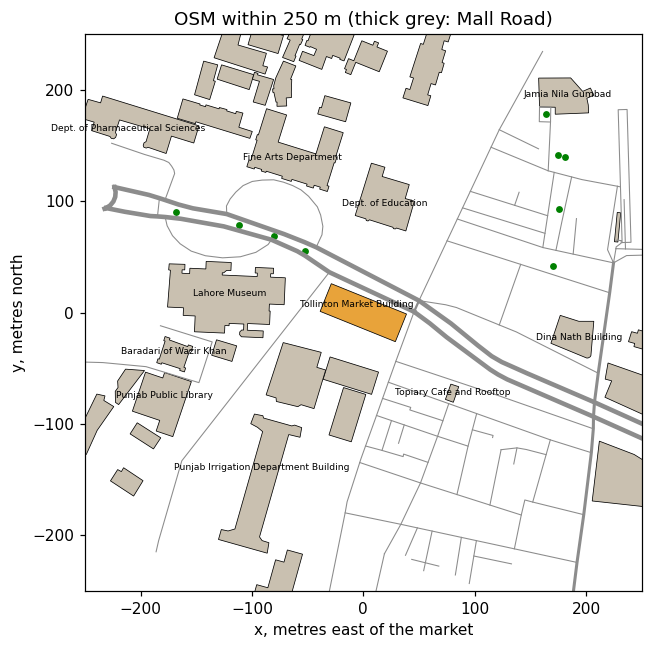

In [4]:
def xy_of(e):
    return np.array([to_xy(p["lat"], p["lon"]) for p in e["geometry"]])


buildings = [e for e in elements if "building" in e["tags"] and e["type"] == "way" and e["tags"]["building"] != "roof"]
roads = [e for e in elements if "highway" in e["tags"] and e["type"] == "way"]
trees = [np.array(to_xy(e["lat"], e["lon"])) for e in elements if e["tags"].get("natural") == "tree"]

foot = xy_of(market)[:-1]                       # four corners (the last point repeats the first)
sides = [(np.linalg.norm(foot[(i + 1) % 4] - foot[i]), math.degrees(math.atan2(*(foot[(i + 1) % 4] - foot[i]))) % 180) for i in range(4)]
for i, (length, bearing) in enumerate(sides):
    print(f"side {i}: {length:5.1f} m, bearing {bearing:5.1f} deg")
L_MARKET, W_MARKET = max(s[0] for s in sides), min(s[0] for s in sides)
BEARING = next(b for s, b in sides if s == L_MARKET)
print(f"footprint {L_MARKET:.1f} m x {W_MARKET:.1f} m = {L_MARKET * W_MARKET:.0f} m2; long axis points {BEARING:.0f} deg (east-south-east)")

fig, ax = plt.subplots(figsize=(7, 6))
width = {"primary": 3, "secondary": 2, "tertiary": 1.5}
for r in roads:
    g = xy_of(r); ax.plot(g[:, 0], g[:, 1], color="0.55", lw=width.get(r["tags"]["highway"], 0.7))
for b in buildings:
    g = xy_of(b); is_m = b["id"] == market["id"]
    ax.fill(g[:, 0], g[:, 1], color="#e8a33a" if is_m else "#c9c0b0", ec="k", lw=0.5)
    name = b["tags"].get("name:en", b["tags"].get("name", ""))
    if name and all(ord(ch) < 128 for ch in name) and abs(g[:, 0].mean()) < 230 and abs(g[:, 1].mean()) < 230:
        ax.text(g[:, 0].mean(), g[:, 1].mean(), name.replace("Historic ", ""), fontsize=6, ha="center")
if trees:
    ax.scatter(*np.array(trees).T, color="green", s=12, label="trees")
ax.set_aspect("equal"); ax.set_xlim(-250, 250); ax.set_ylim(-250, 250)
ax.set_xlabel("x, metres east of the market"); ax.set_ylabel("y, metres north"); ax.set_title("OSM within 250 m (thick grey: Mall Road)")
plt.tight_layout(); plt.show()

The market (orange) is a rectangle 72.8 m long and 26.8 m wide, nearly 2,000 m², with its long side pointing
112° (east-south-east), parallel to Mall Road, the thick grey lines running across the map. The museum, the YMCA, the
Punjab Public Library and the university departments are its neighbours. Two facts follow for the picture. The long
façade that faces Mall Road faces 22° (north-north-east): a direction the sun reaches only on summer mornings and
evenings, so the time of day must be chosen with care. And a viewer standing on Mall Road looks at the market across
the road, which is where we will put our camera.

# Heights from a photograph

The map has no heights, so we measure them from a photograph taken square to the front, using **proportion**: in
such a photo, heights and widths on the façade are drawn at the same scale. We need one known length to set that scale.
The two green cupolas are a good ruler: from the oblique photos on Wikimedia Commons, each sits about 15 % of the
building's length in from its end, so they are about 0.70 × 72.8 = 51 m apart. In the frontal photo they are 650
pixels apart, which gives the scale. The rows of the ground, the verandah eave, the main eave, the roof's visible top
edge and the cupola tops were read off the photo with an image viewer.

Two corrections are needed, and both are physics of the camera. First, the photo is not perfectly square, so the
result is uncertain by roughly ±15 %. Second, the **ridge** is set back from the façade, about 10 m behind it, so it is
farther from the camera and appears lower than it is (things farther away look smaller). Rather than trust its
apparent height, we take the roof's slope from the side photos, about 35°, and compute the ridge from the eave.

scale: 650 px for 50.9 m = 12.8 px per metre
  ground                     row 390 ->   0.0 m above the ground
  verandah eave              row 335 ->   4.3 m above the ground
  main eave                  row 230 ->  12.5 m above the ground
  roof top edge (apparent)   row 168 ->  17.4 m above the ground
  cupola top                 row  60 ->  25.9 m above the ground
heights used: eave 12.5 m, verandah 4.3 m, wall_width 20.8 m, ridge 19.8 m, cupola_top 25.9 m


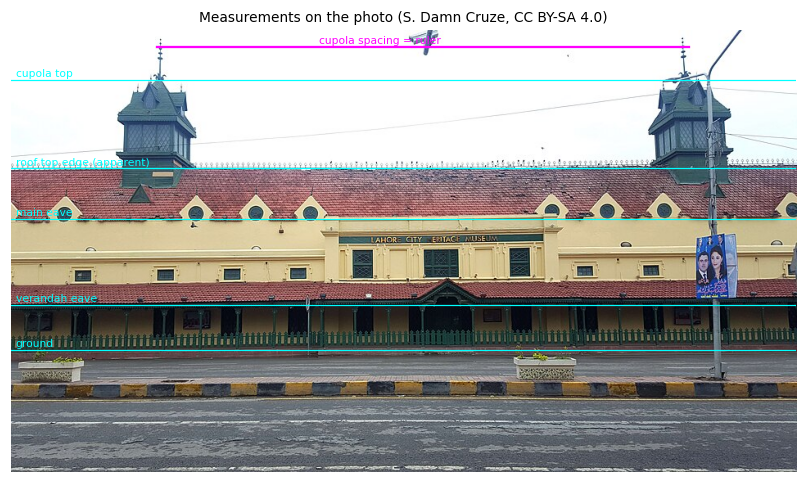

In [5]:
photo = Image.open(DATA / "tollinton_front_2018.jpg")
ROWS = {"ground": 390, "verandah eave": 335, "main eave": 230, "roof top edge (apparent)": 168, "cupola top": 60}
CUPOLA_PX, CUPOLA_M = 828 - 178, 0.70 * L_MARKET
scale = CUPOLA_PX / CUPOLA_M
print(f"scale: {CUPOLA_PX} px for {CUPOLA_M:.1f} m = {scale:.1f} px per metre")
for k, row in ROWS.items():
    print(f"  {k:26s} row {row:3d} -> {(ROWS['ground'] - row) / scale:5.1f} m above the ground")

VERANDA = 3.0                                   # depth of the verandah, from the photos
H = dict(eave=(ROWS["ground"] - ROWS["main eave"]) / scale,
         verandah=(ROWS["ground"] - ROWS["verandah eave"]) / scale)
H["wall_width"] = W_MARKET - 2 * VERANDA
H["ridge"] = H["eave"] + H["wall_width"] / 2 * math.tan(math.radians(35))
H["cupola_top"] = (ROWS["ground"] - ROWS["cupola top"]) / scale
print("heights used: " + ", ".join(f"{k} {v:.1f} m" for k, v in H.items()))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.imshow(photo)
for k, row in ROWS.items():
    ax.axhline(row, color="cyan", lw=0.8); ax.text(5, row - 4, k, color="cyan", fontsize=7)
ax.plot([178, 828], [20, 20], color="magenta"); ax.text(450, 15, "cupola spacing = ruler", color="magenta", fontsize=7, ha="center")
ax.set_axis_off(); ax.set_title("Measurements on the photo (S. Damn Cruze, CC BY-SA 4.0)", fontsize=9)
plt.tight_layout(); plt.show()

The scale is about 12.8 pixels per metre. The main walls are about 12.5 m high (two tall Victorian storeys), the
verandah eave 4.3 m, and the cupolas reach about 26 m. The roof's apparent top edge would put the ridge at only 17.4 m,
but that edge is about 10 m behind the façade and so looks lower than it is; with a 35° slope over half the wall width
the ridge is about 20 m. These are estimates, good to perhaps ±15 %, and they are written down so anyone with a
better measurement (a survey, a LiDAR scan, or a shadow on a satellite image: height = shadow length × tan(sun
elevation)) can replace them.

# Colours from a photograph

Where should an 8-bit palette come from? For a real place, from the place. A photograph contains hundreds of
thousands of colours; we want a dozen that represent it. **k-means clustering** finds them: start with *k* random
colours, give every pixel to the nearest one, move each colour to the average of its pixels, and repeat until
nothing changes. The final averages are the palette. Then we name the materials by sampling the photo at a point on
each (wall, roof, cupola, kerb, road) and taking the nearest palette colour.

The photo was taken under cloud, so it shows each surface under soft, even light. In sunshine a surface is brighter
where it faces the sun. **Lambert's cosine law** says the light a matte surface receives from the sun is
proportional to the cosine of the angle between the surface's outward direction (its *normal*) and the sun, plus a
steady share from the whole sky. We use it to make three tones per material, in shade, half lit and fully lit:
brightness ∝ E_sky + E_sun cos θ, with the sky giving about 45 % as much as direct sun on a facing wall.

sky patch [255. 255. 255.] (clipped); road patch [100. 106. 113.] -> channel gains [1.063 1.003 0.941]


wall           1962 pixels kept -> median colour [225 200 152]  (nearest k-means colour: no. 5)
roof           7453 pixels kept -> median colour [161 115 117]  (nearest k-means colour: no. 9)
cupola         1628 pixels kept -> median colour [ 91 120 136]  (nearest k-means colour: no. 3)
railing        6130 pixels kept -> median colour [32 55 46]  (nearest k-means colour: no. 4)
kerb yellow     530 pixels kept -> median colour [161 117  60]  (nearest k-means colour: no. 9)
kerb dark      5417 pixels kept -> median colour [54 56 60]  (nearest k-means colour: no. 4)
road          55990 pixels kept -> median colour [106 106 106]  (nearest k-means colour: no. 3)
window         1255 pixels kept -> median colour [38 56 56]  (nearest k-means colour: no. 4)


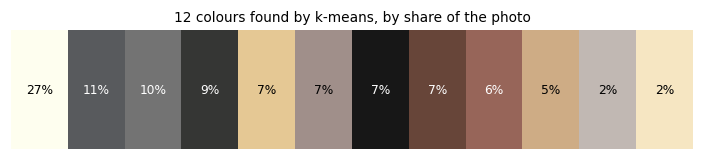

wall tones (shade, half, lit): [(105, 93, 70), (157, 139, 106), (225, 200, 152)]


In [6]:
def kmeans(X, k, iters=25, seed=0):
    rng = np.random.default_rng(seed)
    C = X[rng.choice(len(X), k, replace=False)].astype(float)
    for _ in range(iters):
        label = ((X[:, None, :] - C[None]) ** 2).sum(2).argmin(1)
        C = np.array([X[label == j].mean(0) if (label == j).any() else C[j] for j in range(k)])
    return C, label


px = np.asarray(photo.convert("RGB"), dtype=float)
# White balance: a surface we know to be neutral grey should come out grey; any tint it has is the camera's.
# The overcast sky is the usual choice, but here it is overexposed (every channel at 255), so it carries no colour
# information. Asphalt is close to neutral, so we use the road instead, and scale each channel to make it grey.
sky_patch = np.median(px[20:50, 300:700].reshape(-1, 3), axis=0)
grey = np.median(px[460:530, 100:900].reshape(-1, 3), axis=0)
gain = grey.mean() / grey
px = np.clip(px * gain, 0, 255)
print("sky patch", sky_patch.round(), "(clipped); road patch", grey.round(), "-> channel gains", gain.round(3))
sample = px[::4, ::4].reshape(-1, 3)
centres, label = kmeans(sample, 12)
share = np.bincount(label, minlength=12) / len(label)
order = np.argsort(-share)
# Each material is measured over a patch of the photo, keeping only pixels that pass a simple colour rule, so that
# moss on the tiles or the dark gaps between kerb stones do not spoil the average. Boxes are (x0, y0, x1, y1).
PATCH = {"wall": ((420, 240, 640, 262), lambda r, g, b: r > 180),
         "roof": ((250, 172, 620, 200), lambda r, g, b: r > g + 30),
         "cupola": ((140, 65, 215, 95), lambda r, g, b: g > r),
         "railing": ((60, 372, 900, 384), lambda r, g, b: g > r + 10),
         "kerb yellow": ((0, 432, 960, 444), lambda r, g, b: (r > 150) & (r > b + 60)),
         "kerb dark": ((0, 432, 960, 444), lambda r, g, b: (r < 90) & (abs(r - b) < 25)),
         "road": ((100, 460, 900, 530), lambda r, g, b: r > 0),
         "window": ((505, 268, 545, 300), lambda r, g, b: r < 90)}
material = {}
for name, ((x0, y0, x1, y1), rule) in PATCH.items():
    patch = px[y0:y1, x0:x1].reshape(-1, 3)
    keep = patch[rule(*patch.T)]
    material[name] = np.median(keep, axis=0).round().astype(int)
    near = order.tolist().index(((centres - material[name]) ** 2).sum(1).argmin())
    print(f"{name:12s} {len(keep):6d} pixels kept -> median colour {material[name]}  (nearest k-means colour: no. {near + 1})")

fig, ax = plt.subplots(figsize=(8, 1.4))
ax.imshow(centres[order][None].astype(np.uint8), aspect="auto")
for i, j in enumerate(order):
    ax.text(i, 0, f"{share[j] * 100:.0f}%", ha="center", va="center", fontsize=8, color="w" if centres[j].mean() < 128 else "k")
ax.set_axis_off(); ax.set_title("12 colours found by k-means, by share of the photo", fontsize=9); plt.show()

E_SKY, E_SUN = 0.7, 1.0
TONE_COS = (0.0, 0.35, 0.8)                     # shade, half lit, fully lit


def ramp(rgb):
    ref = E_SKY + E_SUN * 0.8                    # the bright overcast photo is treated as the sunlit tone
    return [tuple(int(min(255, c * (E_SKY + E_SUN * k) / ref)) for c in rgb) for k in TONE_COS]


print("wall tones (shade, half, lit):", ramp(material["wall"]))

Three things happened here, each a lesson. **White balance**: the photo's sky is overexposed, every channel at 255,
so it cannot tell us the camera's tint; the asphalt, which is close to neutral grey, could, and it was slightly blue
(100, 106, 114). Scaling red up 7 % and blue down 6 % makes it grey and corrects every other colour the same way.
**The palette strip** shows the photo's twelve k-means colours by share: the clipped white sky (27 %), greys of road and
pavement, then the plaster yellows and tile reds; no cluster is green, because the cupolas and railing are too small a
share of the picture. **Measuring materials**: k-means alone mixes small things into
big clusters (the cluster nearest the kerb stones' ochre is a tile red), so each material is measured directly as the
median of a patch, keeping only pixels that pass a colour rule. The wall is a warm yellow (226, 200, 150), the roof a
faded terracotta (162, 116, 116), the cupolas a weathered blue-green, the railing dark green, the kerb ochre and
charcoal. Lambert's law then gives three tones per material; the wall's shade tone is under half as bright as its
sunlit tone, as on a sunny Lahore morning.

# The sun over Lahore

Light and shadow depend on where the sun is. Its position follows from astronomy: the Earth's axis is tilted 23.44°,
so through the year the sun's **declination** (its latitude in the sky) swings between +23.44° in June and −23.44° in
December; and the Earth turns 15° an hour, which sets the **hour angle**. Spherical trigonometry turns latitude,
declination and hour angle into the sun's **elevation** above the horizon and its **azimuth** (compass direction).
We use the formulas of the US National Oceanic and Atmospheric Administration (NOAA), which also correct for the
Earth's elliptical orbit (the *equation of time*).

A check we can do by hand: at local solar noon the elevation is 90° − latitude + declination: 81.9° at the June
solstice and 35.0° at the December solstice for Lahore.

2026-06-21: highest 81.9 deg at 12:04 PKT
2026-12-21: highest 35.0 deg at 12:00 PKT
chosen moment: 2026-06-21 07:30 PKT, sun elevation 29.7 deg, azimuth 79.2 deg
angle between sun and Mall Road facade: 57 deg -> lit


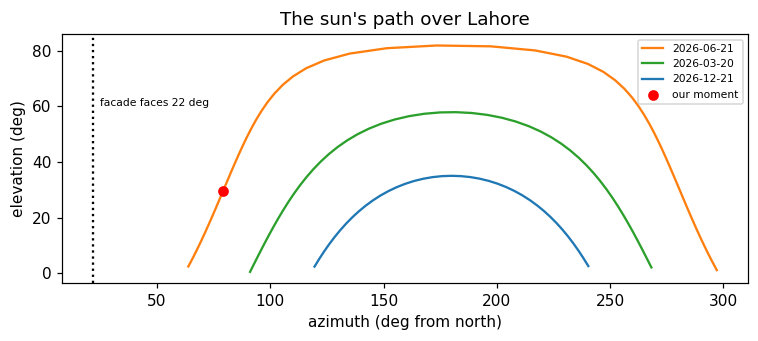

In [7]:
def sun_position(day, hour, lat=LAT0, lon=LON0, tz=5.0):
    """Elevation and azimuth (degrees) of the sun; hour is local clock time, tz hours ahead of UTC (Pakistan: 5)."""
    n = day.timetuple().tm_yday
    g = 2 * math.pi / 365 * (n - 1 + (hour - tz - 12) / 24)
    eqt = 229.18 * (0.000075 + 0.001868 * math.cos(g) - 0.032077 * math.sin(g) - 0.014615 * math.cos(2 * g) - 0.040849 * math.sin(2 * g))
    decl = (0.006918 - 0.399912 * math.cos(g) + 0.070257 * math.sin(g) - 0.006758 * math.cos(2 * g)
            + 0.000907 * math.sin(2 * g) - 0.002697 * math.cos(3 * g) + 0.00148 * math.sin(3 * g))
    solar_minutes = hour * 60 + eqt + 4 * lon - 60 * tz
    ha = math.radians(solar_minutes / 4 - 180)
    phi = math.radians(lat)
    elev = math.asin(math.sin(phi) * math.sin(decl) + math.cos(phi) * math.cos(decl) * math.cos(ha))
    az = math.atan2(math.sin(ha), math.cos(ha) * math.sin(phi) - math.tan(decl) * math.cos(phi)) + math.pi
    return math.degrees(elev), math.degrees(az) % 360


def sun_vector(elev, az):
    e, a = math.radians(elev), math.radians(az)
    return np.array([math.cos(e) * math.sin(a), math.cos(e) * math.cos(a), math.sin(e)])


for d in (date(2026, 6, 21), date(2026, 12, 21)):
    best = max((sun_position(d, h / 60)[0], h) for h in range(10 * 60, 14 * 60))
    print(f"{d}: highest {best[0]:.1f} deg at {best[1] // 60}:{best[1] % 60:02d} PKT")

DAY, HOUR = date(2026, 6, 21), 7.5
ELEV, AZ = sun_position(DAY, HOUR)
SUN = sun_vector(ELEV, AZ)
facade_normal = BEARING - 90                    # the façade facing Mall Road points 22 deg
print(f"chosen moment: {DAY} 07:30 PKT, sun elevation {ELEV:.1f} deg, azimuth {AZ:.1f} deg")
print(f"angle between sun and Mall Road facade: {abs((AZ - facade_normal + 180) % 360 - 180):.0f} deg -> lit")

fig, ax = plt.subplots(figsize=(7, 3.2))
for d, col in ((date(2026, 6, 21), "tab:orange"), (date(2026, 3, 20), "tab:green"), (date(2026, 12, 21), "tab:blue")):
    hrs = np.arange(5, 20.01, 0.25); pos = np.array([sun_position(d, h) for h in hrs]); up = pos[:, 0] > 0
    ax.plot(pos[up, 1], pos[up, 0], color=col, label=str(d))
ax.axvline(facade_normal, color="k", ls=":"); ax.text(facade_normal + 3, 60, "facade faces 22 deg", fontsize=7)
ax.scatter([AZ], [ELEV], color="red", zorder=5, label="our moment")
ax.set_xlabel("azimuth (deg from north)"); ax.set_ylabel("elevation (deg)"); ax.legend(fontsize=7); ax.set_title("The sun's path over Lahore")
plt.tight_layout(); plt.show()

The checks pass: the computed noon elevations, 81.9° in June and 35.0° in December, match the hand formula to the
decimal. Noon falls at 12:04 in June and 12:00 in December: Pakistan's clocks are set for 75° E, Lahore lies 0.7°
west of that, which makes its noon about 3 minutes late, and the equation of time adds about 2 minutes in June and
takes about 2 away in December. The plot shows the sun's path on three days. Only in summer does the sun rise north of
east (azimuth below 90°) and so reach the façade facing 22°, and only in the early morning. At 07:30 on 21 June the
sun is about 30° high and 79° round from north, 57° from straight-on to the façade: the long front is lit at a
slant, and the east end, facing 112°, much more directly. That is the moment we draw.

# A 3D model from a footprint

A 3D model for a renderer is a list of flat **faces**, each a polygon of 3D points with a material. We describe the
market in its own coordinates, *s* along its length, *t* across it (positive towards Mall Road) and *z* up, and turn
them into map coordinates with the building's centre and axes. Everything is generated from the few numbers measured
above: walls from the footprint, a pitched roof to the ridge, stepped (Dutch) gables at the ends, a lean-to verandah
on posts, dormers along the roof, rows of windows, and two cupolas.

Each face also needs its **normal**, the direction it faces, for lighting and to know which side is outside. **Newell's
method** computes it for any flat polygon by summing over its edges; we then make sure it points away from the inside
of the solid.

370 faces in the market model, of which 94 are windows


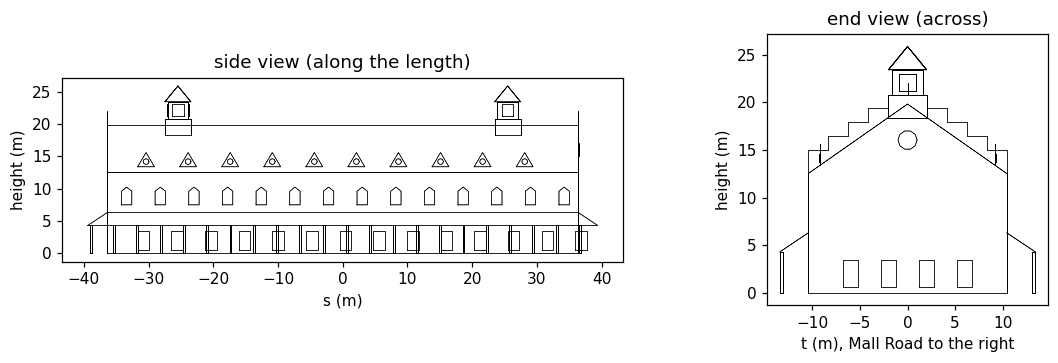

In [8]:
CEN = foot.mean(0)
A = np.array([math.sin(math.radians(BEARING)), math.cos(math.radians(BEARING))])     # along the length
B = np.array([-A[1], A[0]])                                                          # across, rotated 90 deg
mall = [r for r in roads if r["tags"]["highway"] == "primary"]
nearest_road = min((p for r in mall for p in xy_of(r)), key=lambda p: np.linalg.norm(p - CEN))
if np.dot(nearest_road - CEN, B) < 0:
    B = -B                                                                           # t > 0 points to Mall Road


def W(s, t, z):
    p = CEN + s * A + t * B
    return np.array([p[0], p[1], z])


def newell(pts):
    n = np.zeros(3)
    for p, q in zip(pts, np.roll(pts, -1, axis=0)):
        n += [(p[1] - q[1]) * (p[2] + q[2]), (p[2] - q[2]) * (p[0] + q[0]), (p[0] - q[0]) * (p[1] + q[1])]
    return n / (np.linalg.norm(n) or 1)


FACES = []


def face(pts, mat, inside=None, decal_of=None, two_sided=False, group="model"):
    pts = np.array(pts, float)
    n = newell(pts)
    if inside is not None and np.dot(n, pts.mean(0) - inside) < 0:
        n = -n
    if decal_of is not None:
        n = FACES[decal_of]["n"]                 # a window faces the way its wall faces
    FACES.append(dict(pts=pts, mat=mat, n=n, decal_of=decal_of, two_sided=two_sided, group=group))
    return len(FACES) - 1


def box(s0, s1, t0, t1, z0, z1, mat, group="model"):
    inside = W((s0 + s1) / 2, (t0 + t1) / 2, (z0 + z1) / 2)
    c = [(s0, t0), (s1, t0), (s1, t1), (s0, t1)]
    ids = [face([W(*c[i], z0), W(*c[(i + 1) % 4], z0), W(*c[(i + 1) % 4], z1), W(*c[i], z1)], mat, inside, group=group) for i in range(4)]
    ids.append(face([W(*p, z1) for p in c], mat, inside, group=group))
    return ids


def window(parent, s, t_face, z0, z1, w, out, arch=True):
    """A dark opening on a wall: a rectangle with a pointed top, a hair in front of the wall."""
    t = t_face + 0.05 * out
    pts = [W(s - w / 2, t, z0), W(s + w / 2, t, z0), W(s + w / 2, t, z1)] + ([W(s, t, z1 + w * 0.4)] if arch else []) + [W(s - w / 2, t, z1)]
    face(pts, "window", decal_of=parent)


def build_market():
    L, Wm, He, Hr, Hv = L_MARKET, H["wall_width"], H["eave"], H["ridge"], H["verandah"]
    inside = W(0, 0, He / 2)
    for side in (+1, -1):                                        # long walls with two rows of windows
        wall = face([W(-L / 2, side * Wm / 2, 0), W(L / 2, side * Wm / 2, 0), W(L / 2, side * Wm / 2, He), W(-L / 2, side * Wm / 2, He)], "wall", inside)
        for s in np.arange(-L / 2 + 3, L / 2 - 2, 5.2):
            window(wall, s, side * Wm / 2, 7.5, 9.6, 1.6, side)
            window(wall, s + 2.6, side * Wm / 2, 0.6, 3.4, 1.8, side, arch=False)
        face([W(-L / 2, side * Wm / 2, He), W(L / 2, side * Wm / 2, He), W(L / 2, 0, Hr), W(-L / 2, 0, Hr)], "roof", inside)
        for s in np.arange(-L / 2 + 6, L / 2 - 4, 6.5):          # dormers: small gables standing on the roof
            t = side * (Wm / 2 - 1.2); zb = He + 1.2 * math.tan(math.radians(35))
            d = face([W(s - 1.3, t, zb), W(s + 1.3, t, zb), W(s, t, zb + 2.2)], "wall", inside)
            face([W(s + 0.45 * math.cos(k), t + 0.05 * side, zb + 0.8 + 0.45 * math.sin(k)) for k in np.linspace(0, 2 * math.pi, 8, endpoint=False)], "window", decal_of=d)
    for end in (+1, -1):                                         # stepped Dutch gables at both ends
        steps, prof = 5, []
        for k in range(steps):
            t0, t1 = Wm / 2 * (1 - k / steps), Wm / 2 * (1 - (k + 1) / steps)
            z = He + (Hr - He) * (k + 1) / steps + 1.0
            prof += [(t0, z), (t1, z)]
        outline = [(Wm / 2, 0), (Wm / 2, He)] + prof + [(0, Hr + 2.2)] + [(-t, z) for t, z in reversed(prof)] + [(-Wm / 2, He), (-Wm / 2, 0)]
        g = face([W(end * L / 2, t, z) for t, z in outline], "wall", inside)
        face([W(end * (L / 2 + 0.05), 1.0 * math.cos(k), He + 3.5 + 1.0 * math.sin(k)) for k in np.linspace(0, 2 * math.pi, 10, endpoint=False)], "window", decal_of=g)
        for t in (-6, -2, 2, 6):
            face([W(end * (L / 2 + 0.05), t + dt, z) for dt, z in ((-0.8, 0.6), (0.8, 0.6), (0.8, 3.4), (-0.8, 3.4))], "window", decal_of=g)
    for side in (+1, -1):                                        # lean-to verandah on green posts
        vin = W(0, side * (Wm / 2 + VERANDA / 2), Hv / 2)
        face([W(-L / 2 - VERANDA, side * (Wm / 2 + VERANDA), Hv), W(L / 2 + VERANDA, side * (Wm / 2 + VERANDA), Hv),
              W(L / 2, side * Wm / 2, Hv + 2.0), W(-L / 2, side * Wm / 2, Hv + 2.0)], "roof", vin)
        for s in np.arange(-L / 2 - VERANDA + 0.3, L / 2 + VERANDA, 3.6):
            box(s, s + 0.3, side * (Wm / 2 + VERANDA) - 0.3 * (side > 0), side * (Wm / 2 + VERANDA) + 0.3 * (side < 0), 0, Hv, "railing")
    for s_c in (-0.35 * L, 0.35 * L):                            # two cupolas on the ridge
        box(s_c - 2.0, s_c + 2.0, -2.0, 2.0, Hr - 1.5, Hr + 1.0, "cupola")
        body = box(s_c - 1.6, s_c + 1.6, -1.6, 1.6, Hr + 1.0, Hr + 3.6, "cupola")
        for f in body[:4]:
            p = FACES[f]["pts"]; c = p.mean(0); n = FACES[f]["n"]
            u = (p[1] - p[0]) / np.linalg.norm(p[1] - p[0])
            face([c + n * 0.05 + u * du + np.array([0, 0, dz]) for du, dz in ((-0.9, -0.9), (0.9, -0.9), (0.9, 0.9), (-0.9, 0.9))], "window", decal_of=f)
        apex = W(s_c, 0, H["cupola_top"])
        base = [W(s_c + a, b, Hr + 3.6) for a, b in ((-2.0, -2.0), (2.0, -2.0), (2.0, 2.0), (-2.0, 2.0))]
        for i in range(4):
            face([base[i], base[(i + 1) % 4], apex], "cupola", W(s_c, 0, Hr + 4.5))


build_market()
n_market = len(FACES)
print(n_market, "faces in the market model, of which", sum(f["decal_of"] is not None for f in FACES), "are windows")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for f in FACES:
    p = np.vstack([f["pts"], f["pts"][:1]])
    s = (p[:, :2] - CEN) @ A; t = (p[:, :2] - CEN) @ B
    axes[0].plot(s, p[:, 2], lw=0.4, color="k"); axes[1].plot(t, p[:, 2], lw=0.4, color="k")
axes[0].set_title("side view (along the length)"); axes[1].set_title("end view (across)")
for ax in axes:
    ax.set_aspect("equal"); ax.set_ylabel("height (m)")
axes[0].set_xlabel("s (m)"); axes[1].set_xlabel("t (m), Mall Road to the right")
plt.tight_layout(); plt.show()

The two wireframes are the model seen from the side and from the end, drawn straight from the face list. In the side
view you can count the rhythm of upper windows (every 5.2 m) and ground-floor openings between them, the dormers along
the roof and the two cupolas rising to about 26 m; in the end view the stepped gable climbs above the roof line in five
steps to its top at about 22 m, with the round window, and the verandah roofs lean against both long walls. Every
number in it traces back to the map or the photo.

# The neighbourhood: roads and other buildings

The market does not stand alone. From the same OSM data we lay the roads on the ground as strips of the right width
(from the `lanes` tag where mapped, otherwise a typical width for the road class), add the yellow-and-black kerb
stones that edge Lahore's main roads and dashed lane markings, and raise the other buildings as plain blocks. OSM
gives a height for almost none of them, so we use `building:levels` × 3.2 m where it exists and 9 m otherwise, and
say so. The trees mapped in OSM are added once the camera is placed, since they are drawn as flat cut-outs facing it.

In [9]:
ROAD_W = {"primary": 10.5, "secondary": 8.0, "tertiary": 7.0, "residential": 5.0, "service": 4.0, "living_street": 4.0, "unclassified": 5.0, "pedestrian": 4.0, "footway": 2.0}


def strip(line, width, offset=0.0):
    """Quads covering a polyline: each segment widened by `width`, shifted sideways by `offset`."""
    quads = []
    for p, q in zip(line, line[1:]):
        d = (q - p) / (np.linalg.norm(q - p) or 1); n = np.array([-d[1], d[0]])
        a, b = p + n * offset, q + n * offset
        quads.append([np.r_[a - n * width / 2, 0], np.r_[b - n * width / 2, 0], np.r_[b + n * width / 2, 0], np.r_[a + n * width / 2, 0]])
    return quads


def dashes(line, every, length):
    """Cut a polyline into pieces: `length` metres drawn, the rest of each `every` metres skipped."""
    out, pos = [], 0.0
    for p, q in zip(line, line[1:]):
        seg = np.linalg.norm(q - p); d = (q - p) / (seg or 1)
        for x in np.arange(-(pos % every), seg, every):
            a, b = max(x, 0), min(x + length, seg)
            if b > a:
                out.append((p + d * a, p + d * b))
        pos += seg
    return out


GROUND = []                                       # flat faces drawn first, in this order
for r in sorted(roads, key=lambda r: ROAD_W.get(r["tags"]["highway"], 3)):
    hw = r["tags"]["highway"]
    w = float(r["tags"]["lanes"]) * 3.5 if r["tags"].get("lanes", "").isdigit() else ROAD_W.get(hw, 3)
    line = xy_of(r)
    GROUND += [(q, "road") for q in strip(line, w)]
    if hw == "primary":
        for side in (-1, 1):                     # kerb stones: 1 m yellow, then 1 m dark, along both edges
            for a, b in dashes(line, 2.0, 1.0):
                GROUND += [(q, "kerb yellow") for q in strip(np.array([a, b]), 0.4, side * w / 2)]
                GROUND += [(q, "kerb dark") for q in strip(np.array([b, 2 * b - a]), 0.4, side * w / 2)]
        GROUND += [(q, "marking") for a, b in dashes(line, 9.0, 3.0) for q in strip(np.array([a, b]), 0.2)]

for bld in buildings:
    if bld["id"] == market["id"]:
        continue
    g = xy_of(bld)[:-1]
    if len(g) < 3 or np.abs(g).max() > 260:
        continue
    lev = bld["tags"].get("building:levels", "")
    h = float(bld["tags"]["height"]) if bld["tags"].get("height", "").replace(".", "").isdigit() else float(lev) * 3.2 if lev.isdigit() else 9.0
    inside = np.r_[g.mean(0), h / 2]
    for p, q in zip(g, np.roll(g, -1, axis=0)):
        face([np.r_[p, 0], np.r_[q, 0], np.r_[q, h], np.r_[p, h]], "other", inside, group=bld["id"])
    face([np.r_[p, h] for p in g], "other roof", inside, group=bld["id"])
print(len(GROUND), "ground pieces;", len(FACES) - n_market, "faces for", len({f['group'] for f in FACES}) - 1, "neighbouring buildings")

3694 ground pieces; 397 faces for 29 neighbouring buildings


The ground is now about 3,700 flat pieces: road strips, kerb stones alternating every metre, and lane dashes 3 m long
every 9 m. The neighbouring buildings add a few hundred faces. They are deliberately plain: the picture is about the
market, and the neighbours are there to give it a street, at the heights we could justify.

# A camera

To draw 3D faces on a flat screen we imitate a **pinhole camera**: every point is joined by a straight line to the
eye, and where that line crosses the screen is where the point is drawn. In numbers: express the point in the
camera's own axes (right, up, forward); its screen position is the focal length times right/forward and
up/forward. Dividing by the distance forward is **perspective**: twice as far, half as big. A wider field of view
means a shorter focal length.

A point behind the camera has a negative distance and would be drawn upside down, so polygons crossing the plane just
in front of the eye are **clipped** there first (the Sutherland–Hodgman method: walk round the polygon, keep points in
front, and add a new point wherever an edge crosses the plane).

We stand across Mall Road, 60 m out from the market's front and beyond its east end, at the height of a bus top deck
(4.5 m), and look at a point on the middle of the façade, so that both the long front and the east gable show. The
canvas is 256 × 144 pixels, 16:9, and the field of view 50°.

In [10]:
WP, HP = 256, 144
FOV = 50.0


class Camera:
    def __init__(self, eye, target):
        self.eye = np.asarray(eye, float)
        f = np.asarray(target, float) - self.eye
        self.f = f / np.linalg.norm(f)
        r = np.cross(self.f, [0, 0, 1.0]); self.r = r / np.linalg.norm(r)
        self.u = np.cross(self.r, self.f)
        self.focal = (WP / 2) / math.tan(math.radians(FOV / 2))

    def to_cam(self, pts):
        d = np.atleast_2d(pts) - self.eye
        return np.c_[d @ self.r, d @ self.u, d @ self.f]

    def clip(self, cam_pts, near=0.5):
        out = []
        for p, q in zip(cam_pts, np.roll(cam_pts, -1, axis=0)):
            if p[2] >= near:
                out.append(p)
            if (p[2] >= near) != (q[2] >= near):
                out.append(p + (q - p) * (near - p[2]) / (q[2] - p[2]))
        return np.array(out)

    def project(self, pts):
        c = self.clip(self.to_cam(pts))
        if len(c) < 3:
            return None, None
        return np.c_[WP / 2 + self.focal * c[:, 0] / c[:, 2], HP / 2 - self.focal * c[:, 1] / c[:, 2]], c[:, 2].mean()


EYE = W(0.95 * L_MARKET, W_MARKET / 2 + 60, 4.5)
cam = Camera(EYE, W(0.05 * L_MARKET, 0, 11.0))
corners = [W(s, t, z) for s in (-L_MARKET / 2, L_MARKET / 2) for t in (-W_MARKET / 2, W_MARKET / 2) for z in (0, H["eave"])]
uv = np.array([cam.project(np.array([p]).repeat(3, 0))[0][0] for p in corners])
print(f"focal length {cam.focal:.0f} px; the market's corners land between x = {uv[:, 0].min():.0f}..{uv[:, 0].max():.0f} "
      f"and y = {uv[:, 1].min():.0f}..{uv[:, 1].max():.0f} on a {WP} x {HP} canvas")

focal length 274 px; the market's corners land between x = 22..221 and y = 57..109 on a 256 x 144 canvas


With a 50° field of view the focal length is about 274 pixels. The printout projects the eight corners of the
market's walls: they fall inside the canvas (x from 22 to 221, y from 57 to 109), wide across it and in its lower-middle part, which leaves room above for
the cupolas and the sky. If they had not, we would move the eye or the target and run the cell again; framing a shot
is exactly that loop.

# The sky from scattering

Why is the sky blue? Sunlight is close to the light of a hot body at 5,778 K, described by **Planck's law**, which gives
how much light of each wavelength it emits. Air molecules scatter light with a strength proportional to one over
the wavelength to the fourth power (**Rayleigh scattering**). Multiply the two at a red, a green and a blue
wavelength, and the ratio is the colour of the scattered light: the sky. Near the horizon we look through much more
air, the light is scattered many times and the colours even out towards white; that is why the sky pales downwards.
On a clear morning the sky is darker overhead and paler at the horizon, and dithering mixes the tones in 8-bit fashion.

In [11]:
h_pl, c_l, k_b, T_SUN = 6.626e-34, 2.998e8, 1.381e-23, 5778
lam = np.array([650e-9, 550e-9, 450e-9])
planck = lam ** -5 / (np.exp(h_pl * c_l / (lam * k_b * T_SUN)) - 1)
scattered = planck * lam ** -4
sky_rgb = scattered / scattered.max()
print("sunlight R:G:B      ", (planck / planck.max()).round(2))
print("scattering (1/lam^4)", (lam ** -4 / (lam ** -4).max()).round(2))
print("sky colour R:G:B    ", sky_rgb.round(2))
SKY_TOP = tuple(int(v) for v in 60 + 175 * sky_rgb)
SKY_LOW = tuple(int(v) for v in 255 * (0.35 * sky_rgb + 0.65))
SKY_MID = tuple((np.array(SKY_TOP) + SKY_LOW) // 2)
print("sky tones used:", SKY_TOP, SKY_MID, SKY_LOW)

sunlight R:G:B       [0.88 1.   0.99]
scattering (1/lam^4) [0.23 0.45 1.  ]
sky colour R:G:B     [0.2  0.45 1.  ]
sky tones used: (95, 139, 235) (np.int64(139), np.int64(172), np.int64(245)) (183, 206, 255)


Sunlight itself is nearly white: its red, green and blue parts are within about 15 % of each other. Scattering, by
contrast, favours blue over red by (650/450)⁴ ≈ 4.4. Their product is a sky about five times stronger in blue than in
red: the blue we see. We map it to a deep blue at the top of the canvas and a pale, nearly white blue at the horizon.

# Rendering: drawing it all

Now every piece meets. The **palette** is built from the materials, each in three tones. The renderer then:

1. fills the sky with the dithered gradient;
2. draws the ground pieces (roads, kerbs, markings) flat on the ground;
3. casts **shadows**: every point of the market at height *z* lands on the ground at that point minus
   *z* × (horizontal sun direction / vertical sun component), the straight line of a sunbeam; the shadow is the
   **convex hull** (the smallest enclosing polygon) of the footprint and those landing points, and ground under it
   swaps to its shade tone, the palette trick of the first chapters;
4. skips faces turned away from the eye (**back-face culling**), shades the rest by Lambert's law with the sun, and
   draws them from farthest to nearest (**the painter's algorithm**), each window straight after its wall.

57 palette colours: 3 sky tones and 18 materials x 3 tones


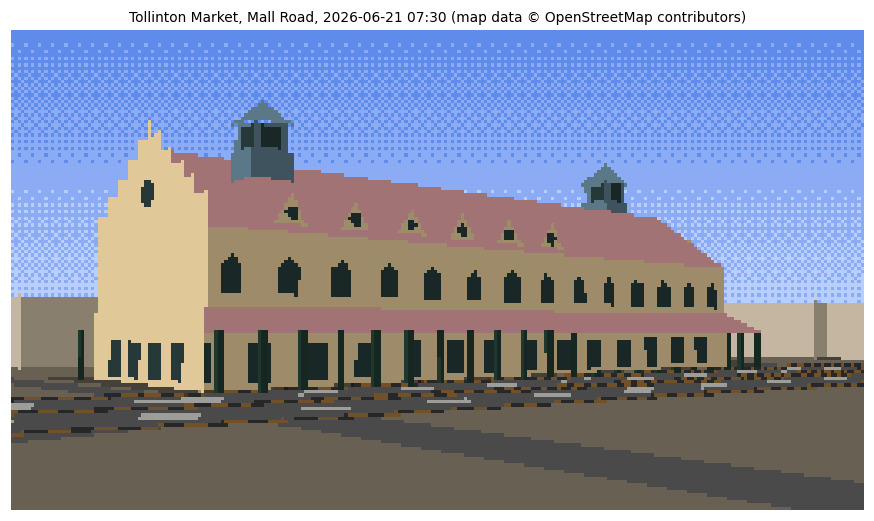

pixels per material (all three tones): {'wall': 5707, 'roof': 3323, 'cupola': 384, 'road': 2802, 'window': 1359, 'other': 1113}


In [12]:
MAT_RGB = {"wall": material["wall"], "roof": material["roof"], "cupola": material["cupola"], "railing": material["railing"],
           "window": material["window"], "road": material["road"], "kerb yellow": material["kerb yellow"],
           "kerb dark": material["kerb dark"], "marking": (225, 225, 220), "other": (196, 182, 160), "other roof": (170, 160, 145),
           "ground": (150, 140, 120), "trunk": (95, 70, 50), "tree": (62, 120, 58), "car white": (225, 225, 228),
           "rickshaw": (40, 140, 80), "car red": (190, 50, 45), "rider": (60, 60, 90)}
PAL, INDEX = [SKY_TOP, SKY_MID, SKY_LOW], {}
for m, rgb in MAT_RGB.items():
    INDEX[m] = len(PAL)
    PAL += ramp(rgb)
print(len(PAL), "palette colours: 3 sky tones and", len(MAT_RGB), "materials x 3 tones")
BAYER = np.array([[0, 8, 2, 10], [12, 4, 14, 6], [3, 11, 1, 9], [15, 7, 13, 5]]) / 16


def convex_hull(points):
    """Andrew's monotone chain: sort the points, then build the lower and upper chains, turning one way only."""
    pts = sorted(map(tuple, points))
    cross = lambda o, a, b: (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])
    lower, upper = [], []
    for p in pts:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)
    for p in reversed(pts):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)
    return np.array(lower[:-1] + upper[:-1])


def shadow_polygons(faces, sun):
    groups = {}
    for f in faces:
        if f["decal_of"] is None and f["group"] != "vehicle":
            groups.setdefault(f["group"], []).append(f["pts"])
    out = []
    for pts in groups.values():
        p = np.vstack(pts)
        ground = p[:, :2] - p[:, 2:3] * sun[:2] / sun[2]
        out.append(np.c_[convex_hull(np.vstack([p[:, :2], ground])), np.zeros(len(convex_hull(np.vstack([p[:, :2], ground]))))])
    return out


def tone(n, mat):
    cos = float(np.dot(n, SUN))
    level = 0 if cos <= 0.05 else 1 if cos < 0.5 else 2
    return INDEX[mat] + level


def billboard_tree(cam, pos, height=7.0, radius=3.2):
    """A tree as cut-outs facing the camera: a trunk and an eight-sided crown."""
    r = cam.r
    base = np.r_[pos, 0]
    face([base - r * 0.3, base + r * 0.3, base + r * 0.3 + [0, 0, height - radius], base - r * 0.3 + [0, 0, height - radius]], "trunk", two_sided=True, group="tree")
    c = base + [0, 0, height - radius * 0.6]
    face([c + r * radius * math.cos(k) + np.array([0, 0, radius * 0.85 * math.sin(k)]) for k in np.linspace(0, 2 * math.pi, 8, endpoint=False)], "tree", two_sided=True, group="tree")


def render(cam, faces, ground):
    img = Image.new("P", (WP, HP)); draw = ImageDraw.Draw(img)
    yy, xx = np.mgrid[0:HP, 0:WP]
    horizon = HP / 2 + cam.focal * cam.f[2] / math.hypot(cam.f[0], cam.f[1])     # where the ground meets the sky
    t = np.clip(yy / max(horizon, 1), 0, 1) * 2
    sky = np.where(t < 1, np.where(t > BAYER[yy % 4, xx % 4], 1, 0), np.where(t - 1 > BAYER[yy % 4, xx % 4], 2, 1))
    img.putdata(sky.astype(np.uint8).ravel().tolist())
    far = np.array([[x, y, 0] for x, y in ((-600, -600), (600, -600), (600, 600), (-600, 600))], float)
    uv, _ = cam.project(far)
    draw.polygon([tuple(p) for p in uv], fill=INDEX["ground"] + 1)
    for pts, mat in ground:
        uv, _ = cam.project(np.array(pts))
        if uv is not None:
            draw.polygon([tuple(p) for p in uv], fill=INDEX[mat] + 1)
    shade = Image.new("L", (WP, HP)); sd = ImageDraw.Draw(shade)
    for poly in shadow_polygons(faces, SUN):
        uv, _ = cam.project(poly)
        if uv is not None:
            sd.polygon([tuple(p) for p in uv], fill=255)
    a = np.array(img); s = np.array(shade) > 0
    is_ground_tone = (a >= 3) & ((a - 3) % 3 == 1)
    a[s & is_ground_tone] -= 1                                                    # half lit -> shade tone
    img = Image.fromarray(a, "P"); draw = ImageDraw.Draw(img)
    items = []
    for i, f in enumerate(faces):
        to_eye = cam.eye - f["pts"].mean(0)
        if not f["two_sided"] and np.dot(f["n"], to_eye) <= 0:
            continue
        uv, depth = cam.project(f["pts"])
        if uv is None:
            continue
        parent = f["decal_of"]
        key = depth if parent is None else cam.to_cam(faces[parent]["pts"])[:, 2].mean()
        items.append((-key, parent is not None, i, uv))
    for _, _, i, uv in sorted(items, key=lambda x: (x[0], x[1])):
        f = faces[i]
        col = INDEX[f["mat"]] + 1 if f["two_sided"] else tone(f["n"], f["mat"])
        draw.polygon([tuple(p) for p in uv], fill=col)
    img.putpalette([v for rgb in PAL for v in rgb])
    return img


for p in trees:
    if np.linalg.norm(p) < 200:
        billboard_tree(cam, p)
still = render(cam, FACES, GROUND)
still.resize((WP * 4, HP * 4), Image.NEAREST).save(DATA / "tollinton_still.png")
plt.figure(figsize=(10, 5.7)); plt.imshow(still.convert("RGB")); plt.axis("off")
plt.title(f"Tollinton Market, Mall Road, {DAY} 07:30 (map data © OpenStreetMap contributors)", fontsize=9); plt.show()
counts = np.bincount(np.array(still).ravel(), minlength=len(PAL))
print("pixels per material (all three tones):", {m: int(counts[INDEX[m]:INDEX[m] + 3].sum()) for m in ("wall", "roof", "cupola", "road", "window", "other")})

This is the still. Read it against the evidence. The long yellow façade faces us across Mall Road with its two rows
of windows, the red roof with its dormers rising behind, the two green cupolas near the ends and the stepped gable at
the east end, all at the proportions measured from the photo and placed where the map puts them. The light is the
07:30 June sun from the east-north-east: the east gable, facing it more squarely, takes the brightest tone, the
long front a half tone, and the walls facing away are in shade. Shadows fall away from us to the west-south-west,
behind the building, as they must with the sun in front and to the right; that is why the street in front is sunlit.
The kerb stones flicker yellow and black along Mall Road, and the plainer blocks around are the neighbours from OSM.
The grey bands across the foreground are not shadows (no shadow polygon reaches them; you can test this) but smaller
OSM roads between us and Mall Road, drawn in the road's colour.

# Traffic on Mall Road

A street needs traffic, and traffic has physics of its own. The **Intelligent Driver Model** (Treiber, Hennecke and
Helbing, 2000) is a standard model in transport research. Each driver accelerates towards a desired speed *v₀* but
keeps a safe gap to the vehicle in front:

*a* = *a*ₘₐₓ [ 1 − (*v*/*v*₀)⁴ − (*s**/*s*)² ],  with  *s** = *s*₀ + *vT* + *v*Δ*v* / (2√(*a*ₘₐₓ *b*)),

where *s* is the actual gap, Δ*v* how much faster we are than the leader, *T* the time headway a driver keeps (about
1.5 s), *s*₀ the gap kept when stopped (2 m) and *b* a comfortable braking rate. The first term is the open road, the
second the vehicle ahead. Different vehicles get different values: a motorbike is nimble, a rickshaw slow. We place
them on the lanes of the Mall Road carriageway in front of the camera, move them along the road's own OSM line, and
integrate with the same semi-implicit Euler steps as the kite in the earlier chapter.

106 vehicles on 770 m of road in 3 lanes; after warm-up speeds 7.5-10.7 m/s, mean 33 km/h
mean speed by kind (km/h): {'car': 35, 'car2': 35, 'rickshaw': 28, 'bike': 32}
mean speed by lane (km/h): {0: 28, 1: 35, 2: 35}


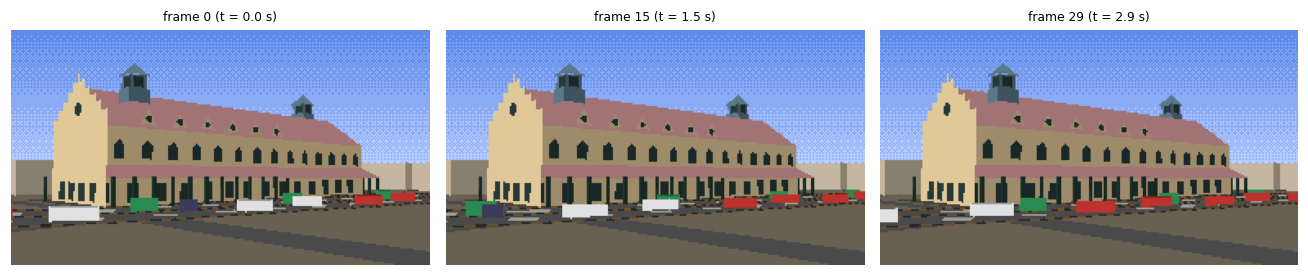

saved data\tollinton_traffic.gif (61 kB)


In [13]:
road_line = max((xy_of(r) for r in mall), key=lambda g: -min(np.linalg.norm(g - EYE[:2], axis=1)))
seg = np.linalg.norm(np.diff(road_line, axis=0), axis=1); cum = np.r_[0, np.cumsum(seg)]
ROAD_LEN = cum[-1]


def along(s):
    s = s % ROAD_LEN
    i = min(np.searchsorted(cum, s) - 1, len(seg) - 1); i = max(i, 0)
    d = (road_line[i + 1] - road_line[i]) / seg[i]
    return road_line[i] + d * (s - cum[i]), d


KINDS = {"car": dict(v0=14.0, a=1.2, b=2.0, T=1.4, L=4.3, Wd=1.8, Ht=1.5, mat="car white"),
         "car2": dict(v0=13.0, a=1.2, b=2.0, T=1.5, L=4.3, Wd=1.8, Ht=1.5, mat="car red"),
         "rickshaw": dict(v0=9.0, a=0.8, b=1.5, T=1.6, L=2.8, Wd=1.4, Ht=1.8, mat="rickshaw"),
         "bike": dict(v0=12.0, a=2.0, b=2.5, T=1.0, L=1.9, Wd=0.6, Ht=1.6, mat="rider")}
rng = np.random.default_rng(11)
vehicles = []
LANE_MIX = {0: [0.0, 0.0, 0.6, 0.4], 1: [0.4, 0.3, 0.0, 0.3], 2: [0.5, 0.4, 0.0, 0.1]}   # rickshaws keep to the left lane
for lane in range(3):
    s = rng.uniform(0, 15)
    while s < ROAD_LEN - 10:
        kind = rng.choice(list(KINDS), p=LANE_MIX[lane])
        vehicles.append(dict(kind=kind, lane=lane, s=s, v=rng.uniform(5, 9), **KINDS[kind]))
        s += rng.uniform(14, 30)


def idm_step(vehicles, dt):
    for lane in range(3):
        vs = sorted([v for v in vehicles if v["lane"] == lane], key=lambda v: v["s"])
        for i, v in enumerate(vs):
            lead = vs[(i + 1) % len(vs)]                       # the road is treated as a loop
            gap = (lead["s"] - v["s"]) % ROAD_LEN - lead["L"]
            s_star = 2.0 + v["v"] * v["T"] + v["v"] * (v["v"] - lead["v"]) / (2 * math.sqrt(v["a"] * v["b"]))
            v["acc"] = v["a"] * (1 - (v["v"] / v["v0"]) ** 4 - (max(s_star, 0) / max(gap, 0.1)) ** 2)
        for v in vs:
            v["v"] = max(0.0, v["v"] + v["acc"] * dt)          # semi-implicit Euler, no reversing
            v["s"] += v["v"] * dt


def vehicle_faces(v, road_half=5.25):
    pos, d = along(v["s"]); n = np.array([-d[1], d[0]])
    centre = pos + n * (-road_half + 1.75 + 3.5 * v["lane"])
    inside = np.r_[centre, v["Ht"] / 2]
    c = [centre + d * a * v["L"] / 2 + n * b * v["Wd"] / 2 for a, b in ((-1, -1), (1, -1), (1, 1), (-1, 1))]
    for i in range(4):
        face([np.r_[c[i], 0.3], np.r_[c[(i + 1) % 4], 0.3], np.r_[c[(i + 1) % 4], v["Ht"]], np.r_[c[i], v["Ht"]]], v["mat"], inside, group="vehicle")
    face([np.r_[p, v["Ht"]] for p in c], v["mat"], inside, group="vehicle")


for _ in range(300):                                           # 30 s of warm-up so the traffic settles
    idm_step(vehicles, 0.1)
speeds = np.array([v["v"] for v in vehicles])
print(f"{len(vehicles)} vehicles on {ROAD_LEN:.0f} m of road in 3 lanes; after warm-up speeds {speeds.min():.1f}-{speeds.max():.1f} m/s, "
      f"mean {speeds.mean() * 3.6:.0f} km/h")
by_kind = {k: np.mean([v['v'] for v in vehicles if v['kind'] == k]) * 3.6 for k in KINDS if any(v['kind'] == k for v in vehicles)}
print("mean speed by kind (km/h):", {k: round(s) for k, s in by_kind.items()})
print("mean speed by lane (km/h):", {lane: round(np.mean([v["v"] for v in vehicles if v["lane"] == lane]) * 3.6) for lane in range(3)})

frames = []
static = len(FACES)
for fno in range(30):
    for _ in range(2):
        idm_step(vehicles, 0.05)
    del FACES[static:]
    for v in vehicles:
        vehicle_faces(v)
    frames.append(render(cam, FACES, GROUND))
del FACES[static:]
big = [f.convert("RGB").resize((WP * 3, HP * 3), Image.NEAREST) for f in frames]
big[0].save(DATA / "tollinton_traffic.gif", save_all=True, append_images=big[1:], duration=100, loop=0)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.6))
for ax, i in zip(axes, (0, 15, 29)):
    ax.imshow(frames[i].convert("RGB")); ax.set_axis_off(); ax.set_title(f"frame {i} (t = {i * 0.1:.1f} s)", fontsize=8)
plt.tight_layout(); plt.show()
print("saved", DATA / "tollinton_traffic.gif", f"({(DATA / 'tollinton_traffic.gif').stat().st_size / 1e3:.0f} kB)")

After half a minute of warm-up the traffic has settled into the pattern the model predicts: each lane moves at the pace
of its slowest vehicles. The left lane, where the rickshaws keep, flows at about 28 km/h, and the bikes sharing it are
held to that pace although they would go faster alone; the two right lanes flow at about 35 km/h. No vehicle reaches
its own desired speed, because the road is busy and every driver keeps a 1 to 1.6 s gap. That is real traffic
behaviour, produced by one equation. The three
frames, a second and a half apart, show the vehicles moving along Mall Road in front of the market, drawn as small
shaded boxes by the same renderer, lit by the same sun, and the 3-second loop is saved as a GIF.

# What you have learned

- Real places start from **open data**: OpenStreetMap gives outlines and streets, with tags that say what is known and
  what is not; cite it and its licence.
- Degrees become metres with a **local tangent plane**, accurate to under a centimetre over a few hundred metres.
- Missing heights can be **measured from a photograph** with a known length as ruler, minding perspective; record the
  uncertainty.
- A palette can be **measured** with k-means clustering, and shaded with **Lambert's cosine law**.
- The **sun's position** follows from the date, time and place; it decides which walls are lit and where shadows fall.
- A building is a list of **faces** with normals; a **pinhole camera**, **clipping**, **back-face culling** and the
  **painter's algorithm** turn them into a picture.
- The sky's colour follows from **Planck's law** and **Rayleigh scattering**.
- Traffic is a **car-following model**; the same integrator that flew the kite drives the rickshaws.